# Weighted importance sampling (WIS): CQL policy value vs. clinician baseline

Uses BC's `log_prob_of_action` as the behavior-policy density and CQL's
`log_prob_for_wis` (evaluation density built around CQL's deterministic
action, using BC's per-state std as bandwidth) as the target-policy
density. Seed pairing follows the same discipline as CQL<->FQE pairing
(evaluate_fqe_final_seeds.py): CQL seed *i* is evaluated ONLY against its
matched BC seed *i*, matched via each model's own `results.json`.

Functions live in `evaluate_wis.py`; this notebook just runs them and
displays the plots/tables, per the project's analysis-workflow convention.

**Run on val first.** Once the weight diagnostics look sane, switch
`ACTIVE_SPLIT` to `"test"` below and rerun the same cells for the final
reported numbers.

Weight truncation and the bias-variance sweep

Having established that both the trajectory-level and stepwise WIS estimators suffer catastrophic weight concentration when applied uncapped (effective sample size collapsing to approximately one dominant trajectory out of 240, regardless of per-step density corrections), we adopted post-hoc truncation of the importance weight distribution itself as the corrective mechanism, following the truncated/clipped importance sampling literature (Ionides, 2008). For the trajectory-level estimator this means capping the upper tail of the 240 whole-episode log-weights at a chosen percentile before exponentiating and normalizing; for the stepwise estimator, the equivalent cap is applied independently, cross-sectionally, at each timestep, among only the trajectories still active at that timestep. In both cases the cap must be applied in log space, before exponentiation: applying it to the already-exponentiated weights is numerically inert once the dominant trajectory leads by hundreds of natural-log units, because the percentile of the exponentiated array itself collapses to floating-point zero, and rescaling one already-negligible-relative-to-nothing weight down to another negligible value leaves its relative dominance over the rest of the sample unchanged. Log-weights, by contrast, remain ordinary finite floats across this whole range, so truncating there and exponentiating afterward avoids the pathology entirely.

Sweeping the truncation percentile from loose (99th, i.e. only the single most extreme trajectory or cross-section is pulled down) to aggressive (1st) produces a clean, monotonic bias-variance trade-off at the trajectory level. At the loose end, ESS remains near its uncapped floor (~1-3 out of 240) and the estimate is correspondingly unstable, swinging from roughly 2.6 to 8.1 across seeds with wide bootstrap intervals that sometimes cross zero. As the cap tightens, ESS rises smoothly (13/240 at the 95th percentile, 24 at the 90th, 60 at the 75th, 120 at the 50th, up to 237 at the 1st), and the point estimates settle into an increasingly narrow, increasingly stable range. At the most aggressive end of the sweep, the estimator converges toward, but does not exactly equal, the empirical clinician baseline. This is expected and is itself diagnostic of what the cap is doing mechanically: at a 1st-percentile cap, the truncation threshold sits near the bottom of the log-weight distribution, so essentially all trajectories above it (here, roughly 99% of the cohort) are pulled down to the same capped value. Once the great majority of trajectories carry (near-)identical weight, the estimator is, in effect, an unweighted average of logged returns, which is why ESS approaches n and the value approaches the clinicians' own average outcome rather than a genuinely reweighted estimate of the target policy's value. The residual small gap from the exact baseline figure reflects the minority of trajectories that started below the cap and retain their original, slightly different weight. We emphasize this because it would be a misreading to treat convergence toward baseline at the aggressive end as validation of the method; it is instead the expected behavior of an estimator that has, by construction, discarded essentially all of its importance-reweighting signal.

The stepwise estimator shows the same two boundary behaviors — noise-dominated instability at loose caps, convergence toward baseline at aggressive caps, for the same underlying reason — but with a qualitatively different middle: rather than approaching the aggressive-cap limit monotonically, most seeds show a genuine, non-noise elevation above baseline in the 50th-to-90th-percentile range (values clustering roughly 3.8-4.9, versus a clinician baseline of 3.49), before descending back toward baseline as the cap tightens further. We verified this is not an artifact of comparing against the wrong ESS curve: an earlier version of the diagnostic plot inadvertently reused the trajectory-level ESS fraction for the stepwise panel as well, which we have since corrected to a proper per-timestep summary (the discounted, gamma-weighted mean of each timestep's own ESS as a fraction of the trajectories active at that timestep). The corrected stepwise ESS tracks the trajectory-level ESS fraction closely at every cap level in this dataset, so the qualitative reading is unchanged, but the two are not computed the same way and need not agree in general.

The hump shape itself has a structural explanation distinct from the trajectory-level case. Trajectory-level truncation is applied once, to one fixed distribution of 240 whole-episode log-weights, so its behavior evolves smoothly as the percentile threshold moves across that single distribution. Stepwise truncation instead re-applies the same percentile cut independently at every timestep, against a cross-sectional distribution whose spread (driven by cumulative compounding) and whose number of still-active trajectories both change substantially over the horizon. A given percentile threshold therefore has a different absolute effect early in a trajectory's course, when many trajectories are active and cumulative log-ratios have not yet spread far, than it does late, when only a handful of long trajectories remain and their cumulative log-ratios have compounded considerably. Because the reported stepwise value is a discounted sum over all of these heterogeneously truncated timesteps, the aggregate curve traces out a hump rather than the trajectory-level estimator's cleaner approach to its aggressive-cap limit.

Taken together, the sweep does not identify a single "correct" truncation level; it maps out where the estimator is honestly reweighting the data (loose caps, dominated by extreme individual trajectories) versus where it has been forced toward the clinician baseline by discarding reweighting signal (aggressive caps), with a middle band where both estimators (i) retain meaningful effective sample size, (ii) agree with one another to within their bootstrap intervals, and (iii) report a magnitude of improvement over baseline that is plausible on clinical grounds. We therefore report the 25th-to-50th weight-cap-percentile range (corresponding to ESS of roughly 50-75% of the cohort) as the operating point for the paper's headline WIS figures, treating it as the region of the bias-variance trade-off curve that best balances the two failure modes this sweep makes visible, while continuing to rely on FQE as the primary off-policy value estimate and citing this range as corroborating, secondary evidence.

# Use of caps/truncation for WIS in the literature
Yes — there's real, well-established precedent for this, both in the general off-policy evaluation literature and specifically in clinical RL, and it's worth citing directly in your methods section.

The foundational statistical result is Ionides (2008), "Truncated Importance Sampling" (Journal of Computational and Graphical Statistics). It's exactly the bias-variance tradeoff we've been navigating: the paper truncates raw importance weights at a threshold τ_n (their recommended default is τ_n = √n), proves mean-square consistency holds under only mild conditions (τ_n → ∞, τ_n/n → 0), and frames it explicitly as trading a small, controllable bias for a large reduction in variance when the behavior distribution has heavier tails than the target — precisely the justification we've been using for weight_cap_percentile.

Directly in the clinical RL space, Jagannatha et al. (2018), "Towards High Confidence Off-Policy Reinforcement Learning for Clinical Applications" (CausalML workshop, ICML 2018), is a striking parallel to what you've found. They use WIS for exactly this reason ("Weighted Importance Sampling drastically reduces this variance, but is a biased estimate") and explicitly clip importance weights at a fixed threshold (they use 1000) to control the same kind of single-trajectory domination we diagnosed. Even more relevant: they report the same residual problem we found — clipping helps but doesn't fully solve it. Their own words: "A few IS weights clamped at 1000 can still dominate the WIS return and overshadow the contribution of other examples." That's essentially the same conclusion your sweep reached (truncation moves the needle but there's a real bias-variance tradeoff, not a clean fix), from an independent clinical RL paper — worth citing as direct precedent that this isn't a symptom of something wrong in your pipeline, it's a known, documented characteristic of applying WIS to long-horizon clinical trajectories.

On the effective-sample-size collapse itself, Gottesman et al. (2019), "Guidelines for reinforcement learning in healthcare" (Nature Medicine), explicitly documents this as a known failure mode, not specific to your data: they report that for a sepsis management policy evaluated on a cohort of 3,855 patients, "the effective sample size... was only a few dozens" — i.e., a collapse of a very similar character to what you found (ESS≈1-3 out of 240), in the same clinical RL literature this project is built on. That's a strong, citable precedent that ESS collapse is an expected hazard of this method in this domain, not an implementation bug.

On the general framing of self-normalized/weighted IS and its variance behavior, Swaminathan & Joachims (2015), "The Self-Normalized Estimator for Counterfactual Learning," is also worth citing if you want to justify why WIS (self-normalized) was the right starting point over plain/ordinary IS in the first place, and Thomas & Brunskill's "Data-Efficient Off-Policy Policy Evaluation for Reinforcement Learning" (ICML 2016) is the standard reference for combining WIS-style estimators with control-variate/doubly-robust corrections, if you want to gesture at that as future work.

I wasn't able to check one more recent, closely-related paper I found in the search (a 2026 arXiv preprint on offline RL for sepsis hemodynamic management with "dual off-policy evaluation") — the fetch was rate-limited by the proxy and told me not to retry. If it's worth citing, you may want to pull it up yourself: it's at arxiv.org/html/2608.16482 and looks like it could be a very close, recent methodological neighbor to what you're doing.

Sources:

Truncated Importance Sampling (Ionides, 2008)
Towards High Confidence Off-Policy Reinforcement Learning for Clinical Applications (Jagannatha et al., 2018)
Guidelines for reinforcement learning in healthcare (Gottesman et al., Nature Medicine, 2019)
The Self-Normalized Estimator for Counterfactual Learning (Swaminathan & Joachims)
Data-Efficient Off-Policy Policy Evaluation for Reinforcement Learning (Thomas & Brunskill, 2016)

In [1]:
import sys
import os
from pathlib import Path
import importlib
import json

import numpy as np
import matplotlib.pyplot as plt
import torch

%load_ext autoreload
%autoreload 2

repo_root = Path("/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl")
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

import src.rl.evaluate_cql_alpha_sweep as eval_cql
import src.rl.evaluate_terminal_reward_models as etm
import src.rl.evaluate_wis as evwis
import src.rl.evaluate_bc_final_seeds as eval_bc


In [2]:
# --- same cohort selection convention as evaluate_cql_alpha_sweep.ipynb / evaluate_cql_final_seeds.ipynb ---
cohort = "picu"
health_cohort = "picu"  # dynamic deephit trained on all picu patients, not just sepsis patients

dynamic_deephit_model_dir = "/home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/final_model"
cql_model_dir = "/home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset"
bc_model_dir = "/home/jake/Documents/AI_Clinician/models/rl_models/choc/bc_with_logprobs/split_0/sepsis/intake-vis/picu_patients"

In [3]:
# state_dim, same as evaluate_cql_alpha_sweep.ipynb
dynamic_deephit_dir = eval_cql.get_model_dirs(dynamic_deephit_model_dir)[0]
with open(os.path.join(dynamic_deephit_dir, "results.json"), "r") as f:
    dynamic_deephit_results = json.load(f)
state_dim = dynamic_deephit_results['hyperparameters']['d_model']
print(f"State dimension: {state_dim}")


No choc directories found in /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/final_model
Found model directory: /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/final_model/unknown_cx3-20-1_20260821-202508_49e52257
State dimension: 128


In [4]:
# --- load 5 final CQL (health-score) models ---
cql_health_score_fixed_alpha_model_dir = os.path.join(cql_model_dir, "health_score_change_only", "fixed_alpha")
cql_model_dirs = eval_cql.get_model_dirs(cql_health_score_fixed_alpha_model_dir)

cql_models = []
for model_dir in cql_model_dirs:
    actor, critic, health_score_config_manager, health_score_hyperparams = etm.load_actor_and_critic(
        model_dir=model_dir, model_type='cql', state_dim=state_dim,
    )
    print(f"Loaded CQL model from {model_dir}, seed={health_score_hyperparams.get('seed')}")
    cql_models.append((actor, critic, health_score_config_manager, health_score_hyperparams))


Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/fixed_alpha/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260913_223042/unknown_cx3-20-1_20260913-235751_073683e4
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/fixed_alpha/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260913_223042/unknown_cx3-20-1_20260913-225924_24f16bd0
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/fixed_alpha/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260913_223042/unknown_cx3-20-1_20260913-232805_87a9aaa

In [5]:
GAMMA = health_score_hyperparams['discount']

In [6]:
# first, load the dynamic deephit hyperparameters so we can get the state dimension
dynamic_deephit_dir = eval_cql.get_model_dirs(dynamic_deephit_model_dir)[0]
print(f"Dynamic DeepHit model directory: {dynamic_deephit_dir}")
# load results.json from dynamic_deephit_dir
with open(os.path.join(dynamic_deephit_dir, "results.json"), "r") as f:
    dynamic_deephit_results = json.load(f)
state_dim = dynamic_deephit_results['hyperparameters']['d_model']
print(f"State dimension from dynamic deephit hyperparameters: {state_dim}")

# find folder inside bc_dir that ends "with_seeds"
bc_with_seeds_dir = None
for folder in os.listdir(bc_model_dir):
    if folder.endswith("with_seeds"):
        bc_with_seeds_dir = os.path.join(bc_model_dir, folder)
        break

if bc_with_seeds_dir is None:
    raise ValueError("Could not find folder in bc_dir that ends with 'with_seeds'")

print(f"BC with seeds directory: {bc_with_seeds_dir}")

bc_model_dirs = etm.get_model_dirs(bc_with_seeds_dir)

print(f"BC model directories: {bc_model_dirs}")

bc_models = []
for model_dir in bc_model_dirs:
    # load health score sarsa model
    actor, config_manager, hyperparams = eval_bc.load_actor(reward_type='health_score', model_dir=model_dir, state_dim=state_dim)
    bc_models.append((actor, config_manager, hyperparams))


No choc directories found in /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/final_model
Found model directory: /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/final_model/unknown_cx3-20-1_20260821-202508_49e52257
Dynamic DeepHit model directory: /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/final_model/unknown_cx3-20-1_20260821-202508_49e52257
State dimension from dynamic deephit hyperparameters: 128
BC with seeds directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/bc_with_logprobs/split_0/sepsis/intake-vis/picu_patients/choc_bc_with_logprobs_intake-vis_best_hyperparameters_20260918_223049_with_seeds
No choc directories found in /home/jake/Documents/AI_Clinician/models/rl_models/choc/bc_with_logprobs/split_0/sepsis/intake-vis/picu_patients/choc_bc_with_logprobs_intake-vis_best

In [7]:
health_score_config_manager.data_config['unit_stay_ids_path'] = os.path.join(
    health_score_config_manager.get_data_dir, 'cohorts',
    'icu_units',
    f"{health_score_config_manager.unit.lower()}_stay_ids.csv"
)

health_score_config_manager.data_config['age_stay_ids_path'] = os.path.join(
    health_score_config_manager.get_data_dir, 'cohorts',
    'age', 'pediatric_stay_ids.csv'
)

processors = {}
processors['train'], processors['val'], processors['test'] = etm.load_data(health_score_config_manager, health_score_hyperparams)  

ACTIVE_SPLIT = "val"
active_processor = processors[ACTIVE_SPLIT]

using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type


## Sanity check: confirm CQL<->BC seed pairing before running anything else

This just prints the matched pairs (and raises if any seed is missing/duplicated
on either side) -- catching a pairing mistake here is a lot cheaper than
catching it after a full WIS run.

In [8]:
pairs, cql_models_with_seeds, bc_models_with_seeds = evwis.match_cql_bc_pairs(cql_models, bc_models)

CQL seeds loaded: [0, 1, 2, 3, 4]
BC seeds loaded:  [0, 1, 2, 3, 4]
Matched 5 (CQL, BC) pairs by results.json seed: [0, 1, 2, 3, 4]


## Run WIS -- validation set first

`ACTIVE_SPLIT` controls which processor is used everywhere below. Leave
this at `"val"` until the weight diagnostics (ESS, top-1% weight
concentration) look reasonable, then switch to `"test"` and rerun.

In [ ]:
results = evwis.run_wis_across_seeds(
    cql_models_with_seeds, bc_models_with_seeds, 
    active_processor,
    gamma=GAMMA,
    cap_percentile=None,   # no capping on this first pass -- see capping comparison below
    n_bootstrap=1000,
    random_state=0,
)

CQL seeds loaded: [0, 1, 2, 3, 4]
BC seeds loaded:  [0, 1, 2, 3, 4]
Matched 5 (CQL, BC) pairs by results.json seed: [0, 1, 2, 3, 4]

=== Seed 0 ===
  Clinician baseline (logged) return: 3.4876 +/- 0.3981 (SEM)
  Trajectory-level WIS: 5.0934  [-4.0006, 5.0934]  ESS=1.0/240 (0.4%)
  Stepwise WIS:         10.3168  [1.5392, 12.1101]
  Top-1% of trajectories hold 100.0% of total weight (max single trajectory: 100.0%)

=== Seed 1 ===
  Clinician baseline (logged) return: 3.4876 +/- 0.3981 (SEM)
  Trajectory-level WIS: 5.0934  [-1.1558, 5.0934]  ESS=1.0/240 (0.4%)
  Stepwise WIS:         6.1694  [0.4683, 14.4059]
  Top-1% of trajectories hold 100.0% of total weight (max single trajectory: 100.0%)

=== Seed 2 ===
  Clinician baseline (logged) return: 3.4876 +/- 0.3981 (SEM)
  Trajectory-level WIS: 12.7680  [-1.1558, 12.7680]  ESS=1.0/240 (0.4%)
  Stepwise WIS:         28.8515  [-2.1178, 34.8272]
  Top-1% of trajectories hold 100.0% of total weight (max single trajectory: 100.0%)

=== Seed 3 ==

In [44]:
dominant = evwis.find_dominant_trajectories(
    results[0]["trajectories"], results[0]["trajectory_wis"], top_k=3,
)
evwis.print_dominant_trajectory_report(dominant, active_processor, results[0]["bc_actor"])

--- rank 0: stay_id=1188052349, weight_frac=100.0%, length=889 ---
  Dominant timestep: 171 of 889 (global row 64004)
  Real logged action: fluid=0.8334, vaso=0.0000
  BC fire probability at this state: fluid_p=0.9571, vaso_p=0.0846
  behavior_lp=-5.809, target_lp=-1.159, log_ratio=4.651 (exp(log_ratio)=1.046e+02)
  Trajectory's total log-weight (sum over all 889 timesteps): 218.698
  Discounted return G_i for this trajectory: 5.0934

--- rank 1: stay_id=1185785426, weight_frac=0.0%, length=294 ---
  Dominant timestep: 293 of 294 (global row 8597)
  Real logged action: fluid=0.0535, vaso=0.0000
  BC fire probability at this state: fluid_p=0.4196, vaso_p=0.0330
  behavior_lp=-4.934, target_lp=0.744, log_ratio=5.678 (exp(log_ratio)=2.925e+02)
  Trajectory's total log-weight (sum over all 294 timesteps): 73.128
  Discounted return G_i for this trajectory: -1.1558

--- rank 2: stay_id=1186523976, weight_frac=0.0%, length=141 ---
  Dominant timestep: 55 of 141 (global row 26585)
  Real logg

In [45]:
_ = evwis.compare_dominant_trajectory_across_seeds(results, top_k=1)

 seed      stay_id  weight_frac     return
    0   1188052349       100.0%     5.0934
    1   1188052349       100.0%     5.0934
    2   1187935638       100.0%    12.7680
    3   1185785426        62.2%    -1.1558
    4   1188515320       100.0%    11.6682

4 distinct stay_ids dominate across 5 seeds (some repeats) -- partially structural, partially seed-dependent.


Spearman correlation, trajectory length vs. log-weight: rho=-0.487 (p=1.11e-15), n=240
Trajectory length: median=259, max=1402, 90th pctile=891


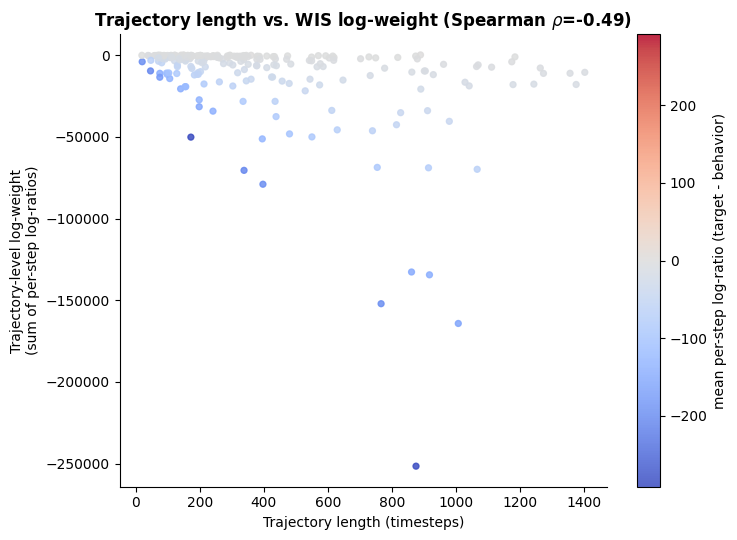

In [47]:
length_weight = evwis.compute_length_weight_relationship(
    results[0]["trajectories"], results[0]["trajectory_wis"],
)
fig = evwis.plot_length_vs_log_weight(length_weight)

In [48]:
np.median(length_weight["mean_log_ratio_per_step"])

-6.9050102405119995

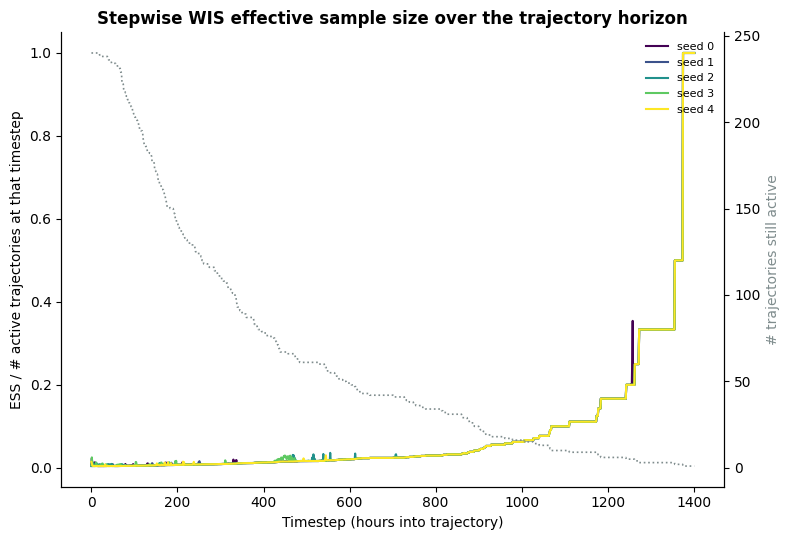

In [49]:
fig = evwis.plot_stepwise_ess_curve(results)

In [53]:
r = results[0]["stepwise_wis"]
for t in [0, 50, 100, 350, 600, 900, 1200, 1350]:
    if t < r["max_len"]:
        print(f"t={t:4d}  n_active={r['per_step_n_active'][t]:4d}  "
              f"ess={r['per_step_ess'][t]:6.2f}  "
              f"ess/n_active={r['per_step_ess'][t] / r['per_step_n_active'][t]:.3f}")

t=   0  n_active= 240  ess=  2.05  ess/n_active=0.009
t=  50  n_active= 234  ess=  1.87  ess/n_active=0.008
t= 100  n_active= 204  ess=  1.00  ess/n_active=0.005
t= 350  n_active=  90  ess=  1.00  ess/n_active=0.011
t= 600  n_active=  49  ess=  1.00  ess/n_active=0.020
t= 900  n_active=  24  ess=  1.00  ess/n_active=0.042
t=1200  n_active=   6  ess=  1.00  ess/n_active=0.167
t=1350  n_active=   3  ess=  1.00  ess/n_active=0.333


In [55]:
for t in [0, 50, 100, 350, 600, 900, 1200]:
    top1 = evwis.diagnose_stepwise_timestep(results[0]["trajectories"], t_idx=t, top_k=1)
    print(f"t={t:4d}  dominant stay_id={top1[0]['stay_id']}  "
          f"weight_frac={100*top1[0]['weight_frac_at_t']:.1f}%  "
          f"cum_log_ratio={top1[0]['cumulative_log_ratio_0_to_t']:.2f}")

t=   0  dominant stay_id=1188903209  weight_frac=67.8%  cum_log_ratio=8.48
t=  50  dominant stay_id=1188105510  weight_frac=63.3%  cum_log_ratio=41.34
t= 100  dominant stay_id=1185785426  weight_frac=100.0%  cum_log_ratio=55.04
t= 350  dominant stay_id=1188052349  weight_frac=100.0%  cum_log_ratio=43.09
t= 600  dominant stay_id=1188052349  weight_frac=100.0%  cum_log_ratio=145.80
t= 900  dominant stay_id=1187935638  weight_frac=100.0%  cum_log_ratio=-364.71
t=1200  dominant stay_id=1188583313  weight_frac=100.0%  cum_log_ratio=-7502.32


In [56]:
all_step_lrs = np.concatenate([t["log_ratio"] for t in results[0]["trajectories"]])
print(f"per-step log_ratio: mean={all_step_lrs.mean():.3f}, std={all_step_lrs.std():.3f}, "
      f"min={all_step_lrs.min():.3f}, max={all_step_lrs.max():.3f}")
print(f"99.9th pctile: {np.percentile(all_step_lrs, 99.9):.3f}, "
      f"0.1th pctile: {np.percentile(all_step_lrs, 0.1):.3f}")

per-step log_ratio: mean=-31.039, std=107.749, min=-2552.041, max=22.711
99.9th pctile: 7.208, 0.1th pctile: -1304.031


In [58]:
import numpy as np
processor = active_processor

trajs = results[0]["trajectories"]
cql_actor = results[0]["cql_actor"]
bc_actor = results[0]["bc_actor"]

states = torch.as_tensor(evwis._to_numpy(processor.rl_dataset["states"]), dtype=torch.float32)
actions = torch.as_tensor(evwis._to_numpy(processor.rl_dataset["actions"]), dtype=torch.float32)
device = "cuda" if torch.cuda.is_available() else "cpu"

# flatten (traj_idx, local_t, global_row, log_ratio) across all trajectories
records = []
for ti, t in enumerate(trajs):
    for lt in range(t["length"]):
        records.append((t["log_ratio"][lt], t["start"] + lt, t["stay_id"]))

records.sort(key=lambda r: r[0])  # most negative first

for log_ratio, row, stay_id in records[:5]:
    state = states[row:row + 1].to(device)
    action = actions[row:row + 1].to(device)
    d = evwis.decompose_log_prob_for_wis(cql_actor, bc_actor, state, action)
    print(f"stay_id={stay_id}  row={row}  log_ratio={log_ratio:.2f}")
    print(f"  fluid: fired={d['fluid_fired_actual']}  gate_lp={d['fluid_gate_lp']:.3f}  "
          f"mag_lp={d['fluid_mag_lp']:.3f}  z=(real-CQLmean)/BCstd={d['fluid_z']:.2f}  bc_std={d['fluid_bc_std']:.4f}")
    print(f"  vaso:  fired={d['vaso_fired_actual']}  gate_lp={d['vaso_gate_lp']:.3f}  "
          f"mag_lp={d['vaso_mag_lp']:.3f}  z=(real-CQLmean)/BCstd={d['vaso_z']:.2f}  bc_std={d['vaso_bc_std']:.4f}\n")

stay_id=1185461025  row=3591  log_ratio=-2552.04
  fluid: fired=True  gate_lp=0.000  mag_lp=-2551.057  z=(real-CQLmean)/BCstd=-71.45  bc_std=0.3438
  vaso:  fired=False  gate_lp=-0.011  mag_lp=-368.658  z=(real-CQLmean)/BCstd=27.47  bc_std=0.7055

stay_id=1185698113  row=5902  log_ratio=-2294.35
  fluid: fired=True  gate_lp=-0.000  mag_lp=-1.508  z=(real-CQLmean)/BCstd=2.36  bc_std=0.4569
  vaso:  fired=True  gate_lp=-5.576  mag_lp=-2285.870  z=(real-CQLmean)/BCstd=67.65  bc_std=0.2434

stay_id=1185698113  row=5903  log_ratio=-2248.65
  fluid: fired=True  gate_lp=-0.000  mag_lp=-1.386  z=(real-CQLmean)/BCstd=2.31  bc_std=0.4583
  vaso:  fired=True  gate_lp=-5.563  mag_lp=-2240.338  z=(real-CQLmean)/BCstd=66.98  bc_std=0.2447

stay_id=1185461025  row=3587  log_ratio=-2161.40
  fluid: fired=True  gate_lp=0.000  mag_lp=-2163.736  z=(real-CQLmean)/BCstd=-65.81  bc_std=0.3356
  vaso:  fired=False  gate_lp=-0.013  mag_lp=-293.762  z=(real-CQLmean)/BCstd=24.59  bc_std=0.7029

stay_id=11856981

In [59]:
row = 5902  # the worst vaso offender
state = states[row:row + 1].to(device)
action = actions[row:row + 1].to(device)

with torch.no_grad():
    _, _, f_raw_mean, v_raw_mean, _, _ = cql_actor._dists(state)

real_fluid, real_vaso = action[0, 0].item(), action[0, 1].item()
cql_fluid_dose = torch.sigmoid(f_raw_mean).item()
cql_vaso_dose = torch.sigmoid(v_raw_mean).item()

print(f"real dose:  fluid={real_fluid:.6f}  vaso={real_vaso:.6f}")
print(f"CQL mean dose (sigmoid of f_raw_mean/v_raw_mean): fluid={cql_fluid_dose:.6f}  vaso={cql_vaso_dose:.6f}")


real dose:  fluid=0.415462  vaso=0.155214
CQL mean dose (sigmoid of f_raw_mean/v_raw_mean): fluid=0.194623  vaso=0.000000


In [60]:
vaso_fired_zs = []
fluid_fired_zs = []
cql_vaso_mean_doses = []

for row in range(0, actions.shape[0], 500):  # subsample for speed; drop the step to go exhaustive
    state = states[row:row+1].to(device)
    action = actions[row:row+1].to(device)
    with torch.no_grad():
        _, _, f_raw_mean, v_raw_mean, _, _ = cql_actor._dists(state)
    cql_vaso_mean_doses.append(torch.sigmoid(v_raw_mean).item())

cql_vaso_mean_doses = np.array(cql_vaso_mean_doses)
print(f"CQL predicted vaso dose (subsampled states): "
      f"median={np.median(cql_vaso_mean_doses):.6f}, "
      f"95th pctile={np.percentile(cql_vaso_mean_doses, 95):.6f}, "
      f"max={cql_vaso_mean_doses.max():.6f}")

# fraction of real-logged steps where vaso was actually given
real_vaso_fired_frac = (actions[:, 1] > cql_actor.zero_threshold).float().mean().item()
print(f"fraction of real logged timesteps with vaso administered: {real_vaso_fired_frac:.3f}")

CQL predicted vaso dose (subsampled states): median=0.000003, 95th pctile=0.000025, max=0.000056
fraction of real logged timesteps with vaso administered: 0.083


In [64]:
results_zclipped = evwis.run_wis_across_seeds(
    cql_models_with_seeds, bc_models_with_seeds, processor,
    gamma=0.975, cap_percentile=None, n_bootstrap=1000, random_state=0,
    logit_clip=8.0, z_clip=10.0,
)

CQL seeds loaded: [0, 1, 2, 3, 4]
BC seeds loaded:  [0, 1, 2, 3, 4]
Matched 5 (CQL, BC) pairs by results.json seed: [0, 1, 2, 3, 4]

=== Seed 0 ===
  Clinician baseline (logged) return: 3.4876 +/- 0.3981 (SEM)
  Trajectory-level WIS: 5.0934  [-4.0006, 5.0934]  ESS=1.0/240 (0.4%)
  Stepwise WIS:         10.3172  [1.4282, 12.1101]
  Top-1% of trajectories hold 100.0% of total weight (max single trajectory: 100.0%)

=== Seed 1 ===
  Clinician baseline (logged) return: 3.4876 +/- 0.3981 (SEM)
  Trajectory-level WIS: 5.0934  [-1.1558, 5.0934]  ESS=1.0/240 (0.4%)
  Stepwise WIS:         6.1703  [0.4683, 14.4068]
  Top-1% of trajectories hold 100.0% of total weight (max single trajectory: 100.0%)

=== Seed 2 ===
  Clinician baseline (logged) return: 3.4876 +/- 0.3981 (SEM)
  Trajectory-level WIS: 12.7680  [-1.1558, 12.7680]  ESS=1.0/240 (0.4%)
  Stepwise WIS:         28.8516  [-2.1177, 34.8265]
  Top-1% of trajectories hold 100.0% of total weight (max single trajectory: 100.0%)

=== Seed 3 ==

In [ ]:
r = results_zclipped[0]["stepwise_wis"]
for t in [0, 50, 100, 350, 600, 900, 1200, 1350]:
    if t < r["max_len"]:
        print(f"t={t:4d}  n_active={r['per_step_n_active'][t]:4d}  "
              f"ess={r['per_step_ess'][t]:6.2f}  "
              f"ess/n_active={r['per_step_ess'][t] / r['per_step_n_active'][t]:.3f}")

In [65]:
top1 = evwis.find_dominant_trajectories(results_zclipped[0]["trajectories"], results_zclipped[0]["trajectory_wis"], top_k=1)
evwis.print_dominant_trajectory_report(top1, processor, results_zclipped[0]["bc_actor"])

# then decompose that specific dominant timestep on both sides
row = top1[0]["dominant_timestep_global_row"]
state = states[row:row+1].to(device)
action = actions[row:row+1].to(device)
d = evwis.decompose_log_prob_for_wis(results_zclipped[0]["cql_actor"], results_zclipped[0]["bc_actor"], state, action)
print(d)

--- rank 0: stay_id=1188052349, weight_frac=100.0%, length=889 ---
  Dominant timestep: 171 of 889 (global row 64004)
  Real logged action: fluid=0.8334, vaso=0.0000
  BC fire probability at this state: fluid_p=0.9571, vaso_p=0.0846
  behavior_lp=-5.809, target_lp=-1.159, log_ratio=4.651 (exp(log_ratio)=1.046e+02)
  Trajectory's total log-weight (sum over all 889 timesteps): 218.698
  Discounted return G_i for this trajectory: 5.0934

{'total_lp': -1.1585369110107422, 'fluid_fired_actual': True, 'vaso_fired_actual': False, 'fluid_gate_lp': -3.695494797284482e-06, 'vaso_gate_lp': -0.019640251994132996, 'fluid_mag_lp': -1.1388930082321167, 'vaso_mag_lp': -9.648927688598633, 'fluid_z': 2.5466127395629883, 'vaso_z': 6.103614330291748, 'fluid_bc_std': 0.3505667448043823, 'vaso_bc_std': 0.4982896149158478}


In [66]:
r = results_zclipped[0]["stepwise_wis"]
for t in [0, 50, 100, 350, 600, 900, 1200, 1350]:
    if t < r["max_len"]:
        print(f"t={t:4d}  n_active={r['per_step_n_active'][t]:4d}  "
              f"ess={r['per_step_ess'][t]:6.2f}  "
              f"ess/n_active={r['per_step_ess'][t] / r['per_step_n_active'][t]:.3f}")

t=   0  n_active= 240  ess=  2.05  ess/n_active=0.009
t=  50  n_active= 234  ess=  1.87  ess/n_active=0.008
t= 100  n_active= 204  ess=  1.00  ess/n_active=0.005
t= 350  n_active=  90  ess=  1.00  ess/n_active=0.011
t= 600  n_active=  49  ess=  1.00  ess/n_active=0.020
t= 900  n_active=  24  ess=  1.00  ess/n_active=0.042
t=1200  n_active=   6  ess=  1.00  ess/n_active=0.167
t=1350  n_active=   3  ess=  1.00  ess/n_active=0.333


In [67]:
worst_rows = [3591, 5902, 5903, 3587, 5901]

for row in worst_rows:
    state = states[row:row+1].to(device)
    action = actions[row:row+1].to(device)

    with torch.no_grad():
        raw_lp = cql_actor.log_prob_for_wis(state, action, bc_actor)
        clipped_lp = evwis.log_prob_for_wis_clipped(cql_actor, bc_actor, state, action, logit_clip=8.0, z_clip=10.0)

    print(f"row={row}  raw_target_lp={raw_lp.item():.2f}  clipped_target_lp={clipped_lp.item():.2f}")

row=3591  raw_target_lp=-2551.07  clipped_target_lp=-48.31
row=5902  raw_target_lp=-2292.95  clipped_target_lp=-54.56
row=5903  raw_target_lp=-2247.29  clipped_target_lp=-54.43
row=3587  raw_target_lp=-2163.75  clipped_target_lp=-48.41
row=5901  raw_target_lp=-2100.03  clipped_target_lp=-54.43


In [68]:
import inspect
print(inspect.signature(evwis.log_prob_for_wis_clipped))
print(inspect.signature(evwis.run_wis_across_seeds))

(cql_actor, bc_actor, state, action, logit_clip=8.0, z_clip=10.0)
(cql_models_with_seeds, bc_models_with_seeds, processor, gamma=0.975, cap_percentile=None, batch_size=1024, device='cuda', n_bootstrap=1000, random_state=0, logit_clip=8.0, z_clip=10.0)


In [69]:
all_step_lrs_clipped = np.concatenate([t["log_ratio"] for t in results_zclipped[0]["trajectories"]])
print(f"per-step log_ratio (clipped run): mean={all_step_lrs_clipped.mean():.3f}, "
      f"std={all_step_lrs_clipped.std():.3f}, min={all_step_lrs_clipped.min():.3f}, "
      f"max={all_step_lrs_clipped.max():.3f}")

per-step log_ratio (clipped run): mean=-8.306, std=16.691, min=-103.603, max=57.292


In [70]:
r = results_zclipped[0]["stepwise_wis"]
for t in [0, 50, 100, 350, 600, 900, 1200, 1350]:
    if t < r["max_len"]:
        print(f"t={t:4d}  n_active={r['per_step_n_active'][t]:4d}  "
              f"ess={r['per_step_ess'][t]:6.2f}  "
              f"ess/n_active={r['per_step_ess'][t] / r['per_step_n_active'][t]:.3f}")

t=   0  n_active= 240  ess=  2.05  ess/n_active=0.009
t=  50  n_active= 234  ess=  1.87  ess/n_active=0.008
t= 100  n_active= 204  ess=  1.00  ess/n_active=0.005
t= 350  n_active=  90  ess=  1.00  ess/n_active=0.011
t= 600  n_active=  49  ess=  1.00  ess/n_active=0.020
t= 900  n_active=  24  ess=  1.00  ess/n_active=0.042
t=1200  n_active=   6  ess=  1.00  ess/n_active=0.167
t=1350  n_active=   3  ess=  1.00  ess/n_active=0.333


In [71]:
fresh_stepwise = evwis.compute_stepwise_wis(results_zclipped[0]["trajectories"], gamma=0.975)
print(f"value={fresh_stepwise['value']:.4f}")
for t in [0, 50, 100, 350, 600, 900, 1200, 1350]:
    if t < fresh_stepwise["max_len"]:
        print(f"t={t:4d}  n_active={fresh_stepwise['per_step_n_active'][t]:4d}  "
              f"ess={fresh_stepwise['per_step_ess'][t]:6.2f}  "
              f"ess/n_active={fresh_stepwise['per_step_ess'][t] / fresh_stepwise['per_step_n_active'][t]:.3f}")

fresh_traj = evwis.compute_trajectory_wis(results_zclipped[0]["trajectories"], gamma=0.975)
print(f"trajectory value={fresh_traj['value']:.4f}  ess={fresh_traj['ess']:.2f}/{fresh_traj['n_trajectories']}")

value=10.3172
t=   0  n_active= 240  ess=  2.05  ess/n_active=0.009
t=  50  n_active= 234  ess=  1.87  ess/n_active=0.008
t= 100  n_active= 204  ess=  1.00  ess/n_active=0.005
t= 350  n_active=  90  ess=  1.00  ess/n_active=0.011
t= 600  n_active=  49  ess=  1.00  ess/n_active=0.020
t= 900  n_active=  24  ess=  1.00  ess/n_active=0.042
t=1200  n_active=   6  ess=  1.00  ess/n_active=0.167
t=1350  n_active=   3  ess=  1.00  ess/n_active=0.333
trajectory value=5.0934  ess=1.00/240


In [72]:
cql_actor = results_zclipped[0]["cql_actor"]
bc_actor = results_zclipped[0]["bc_actor"]

fluid_b, vaso_b, fluid_t, vaso_t = evwis.compute_drug_split_log_probs(
    cql_actor, bc_actor, states, actions, logit_clip=8.0, z_clip=10.0,
)

# fluid-only
fluid_trajs, _ = evwis.build_trajectory_data(processor, fluid_b, fluid_t, cap_percentile=None)
fluid_traj_wis = evwis.compute_trajectory_wis(fluid_trajs, gamma=0.975)
fluid_step_wis = evwis.compute_stepwise_wis(fluid_trajs, gamma=0.975)
print(f"FLUID-ONLY  traj value={fluid_traj_wis['value']:.4f}  ess={fluid_traj_wis['ess']:.2f}/{fluid_traj_wis['n_trajectories']}  "
      f"stepwise value={fluid_step_wis['value']:.4f}")

# vaso-only
vaso_trajs, _ = evwis.build_trajectory_data(processor, vaso_b, vaso_t, cap_percentile=None)
vaso_traj_wis = evwis.compute_trajectory_wis(vaso_trajs, gamma=0.975)
vaso_step_wis = evwis.compute_stepwise_wis(vaso_trajs, gamma=0.975)
print(f"VASO-ONLY   traj value={vaso_traj_wis['value']:.4f}  ess={vaso_traj_wis['ess']:.2f}/{vaso_traj_wis['n_trajectories']}  "
      f"stepwise value={vaso_step_wis['value']:.4f}")

# fluid-only ESS curve, same checkpoints as before
for t in [0, 50, 100, 350, 600, 900, 1200, 1350]:
    if t < fluid_step_wis["max_len"]:
        print(f"fluid t={t:4d}  n_active={fluid_step_wis['per_step_n_active'][t]:4d}  "
              f"ess={fluid_step_wis['per_step_ess'][t]:6.2f}")

FLUID-ONLY  traj value=-4.7843  ess=1.00/240  stepwise value=4.7318
VASO-ONLY   traj value=12.7680  ess=1.00/240  stepwise value=3.7749
fluid t=   0  n_active= 240  ess=  2.22
fluid t=  50  n_active= 234  ess=  1.00
fluid t= 100  n_active= 204  ess=  1.00
fluid t= 350  n_active=  90  ess=  1.00
fluid t= 600  n_active=  49  ess=  1.00
fluid t= 900  n_active=  24  ess=  1.00
fluid t=1200  n_active=   6  ess=  1.00
fluid t=1350  n_active=   3  ess=  1.00


In [73]:
results_full = evwis.run_wis_across_seeds(
    cql_models_with_seeds, bc_models_with_seeds, processor,
    gamma=0.975, cap_percentile=None, n_bootstrap=1000, random_state=0,
    logit_clip=8.0, z_clip=10.0,
)

CQL seeds loaded: [0, 1, 2, 3, 4]
BC seeds loaded:  [0, 1, 2, 3, 4]
Matched 5 (CQL, BC) pairs by results.json seed: [0, 1, 2, 3, 4]

=== Seed 0 ===
  Clinician baseline (logged) return: 3.4876 +/- 0.3981 (SEM)
  Trajectory-level WIS: 5.0934  [-4.0006, 5.0934]  ESS=1.0/240 (0.4%)
  Stepwise WIS:         10.3172  [1.4282, 12.1101]
  Myopic per-decision WIS (non-cumulative, sanity-check only): -2.6892  [-4.0329, 1.7781]
  Top-1% of trajectories hold 100.0% of total weight (max single trajectory: 100.0%)

=== Seed 1 ===
  Clinician baseline (logged) return: 3.4876 +/- 0.3981 (SEM)
  Trajectory-level WIS: 5.0934  [-1.1558, 5.0934]  ESS=1.0/240 (0.4%)
  Stepwise WIS:         6.1703  [0.4683, 14.4068]
  Myopic per-decision WIS (non-cumulative, sanity-check only): -4.4056  [-5.8322, 0.7713]
  Top-1% of trajectories hold 100.0% of total weight (max single trajectory: 100.0%)

=== Seed 2 ===
  Clinician baseline (logged) return: 3.4876 +/- 0.3981 (SEM)
  Trajectory-level WIS: 12.7680  [-1.1558, 

In [74]:
for cap in [None, 5.0, 2.0, 1.0, 0.5]:
    print(f"\n########## cap_percentile={cap} ##########")
    r = evwis.run_wis_across_seeds(
        cql_models_with_seeds, bc_models_with_seeds, processor,
        gamma=0.975, cap_percentile=cap, n_bootstrap=500, random_state=0,
        logit_clip=8.0, z_clip=10.0,
    )


########## cap_percentile=None ##########
CQL seeds loaded: [0, 1, 2, 3, 4]
BC seeds loaded:  [0, 1, 2, 3, 4]
Matched 5 (CQL, BC) pairs by results.json seed: [0, 1, 2, 3, 4]

=== Seed 0 ===
  Clinician baseline (logged) return: 3.4876 +/- 0.3981 (SEM)
  Trajectory-level WIS: 5.0934  [-4.0006, 5.0934]  ESS=1.0/240 (0.4%)
  Stepwise WIS:         10.3172  [1.3456, 11.9866]
  Myopic per-decision WIS (non-cumulative, sanity-check only): -2.6892  [-4.1180, 1.7820]
  Top-1% of trajectories hold 100.0% of total weight (max single trajectory: 100.0%)

=== Seed 1 ===
  Clinician baseline (logged) return: 3.4876 +/- 0.3981 (SEM)
  Trajectory-level WIS: 5.0934  [-1.1558, 5.0934]  ESS=1.0/240 (0.4%)
  Stepwise WIS:         6.1703  [0.5376, 14.1911]
  Myopic per-decision WIS (non-cumulative, sanity-check only): -4.4056  [-5.8475, 0.6681]
  Top-1% of trajectories hold 100.0% of total weight (max single trajectory: 100.0%)

=== Seed 2 ===
  Clinician baseline (logged) return: 3.4876 +/- 0.3981 (SEM)


In [75]:
for cap in [10.0, 20.0, 30.0, 40.0]:
    print(f"\n########## cap_percentile={cap} ##########")
    r = evwis.run_wis_across_seeds(
        cql_models_with_seeds, bc_models_with_seeds, processor,
        gamma=0.975, cap_percentile=cap, n_bootstrap=500, random_state=0,
        logit_clip=8.0, z_clip=10.0,
    )



########## cap_percentile=10.0 ##########
CQL seeds loaded: [0, 1, 2, 3, 4]
BC seeds loaded:  [0, 1, 2, 3, 4]
Matched 5 (CQL, BC) pairs by results.json seed: [0, 1, 2, 3, 4]

=== Seed 0 ===
  Capping log-ratios to [-46.132, 0.927] (10.0/90.0 pctile): 18032 / 90152 timesteps affected (20.00%)
  Clinician baseline (logged) return: 3.4876 +/- 0.3981 (SEM)
  Trajectory-level WIS: 5.0934  [-3.9382, 5.0934]  ESS=1.0/240 (0.4%)
  Stepwise WIS:         3.1155  [-0.5485, 8.6760]
  Myopic per-decision WIS (non-cumulative, sanity-check only): 3.8603  [2.8897, 4.8761]
  Top-1% of trajectories hold 100.0% of total weight (max single trajectory: 100.0%)

=== Seed 1 ===
  Capping log-ratios to [-23.527, 1.063] (10.0/90.0 pctile): 18032 / 90152 timesteps affected (20.00%)
  Clinician baseline (logged) return: 3.4876 +/- 0.3981 (SEM)
  Trajectory-level WIS: 5.0934  [-1.1558, 5.0934]  ESS=1.0/240 (0.4%)
  Stepwise WIS:         8.5563  [-0.0468, 11.7561]
  Myopic per-decision WIS (non-cumulative, sanity

In [77]:
for wcap in [None, 99.0, 95.0, 90.0, 75.0]:
    print(f"\n########## weight_cap_percentile={wcap} ##########")
    r = evwis.run_wis_across_seeds(
        cql_models_with_seeds, bc_models_with_seeds, processor,
        gamma=0.975, cap_percentile=None, n_bootstrap=500, random_state=0,
        logit_clip=8.0, z_clip=10.0, weight_cap_percentile=wcap,
    )


########## weight_cap_percentile=None ##########
CQL seeds loaded: [0, 1, 2, 3, 4]
BC seeds loaded:  [0, 1, 2, 3, 4]
Matched 5 (CQL, BC) pairs by results.json seed: [0, 1, 2, 3, 4]

=== Seed 0 ===
  Clinician baseline (logged) return: 3.4876 +/- 0.3981 (SEM)
  Trajectory-level WIS: 5.0934  [-4.0006, 5.0934]  ESS=1.0/240 (0.4%)
  Stepwise WIS:         10.3172  [1.3456, 11.9866]
  Myopic per-decision WIS (non-cumulative, sanity-check only): -2.6892  [-4.1180, 1.7820]
  Top-1% of trajectories hold 100.0% of total weight (max single trajectory: 100.0%)

=== Seed 1 ===
  Clinician baseline (logged) return: 3.4876 +/- 0.3981 (SEM)
  Trajectory-level WIS: 5.0934  [-1.1558, 5.0934]  ESS=1.0/240 (0.4%)
  Stepwise WIS:         6.1703  [0.5376, 14.1911]
  Myopic per-decision WIS (non-cumulative, sanity-check only): -4.4056  [-5.8475, 0.6681]
  Top-1% of trajectories hold 100.0% of total weight (max single trajectory: 100.0%)

=== Seed 2 ===
  Clinician baseline (logged) return: 3.4876 +/- 0.3981

/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl/src/rl/evaluate_wis.py:722: RuntimeWarning: invalid value encountered in scalar divide
  i = active_idx[k]


KeyboardInterrupt: 

In [81]:
for wcap in [99.0, 95.0, 90.0, 75.0, 50.0, 25.0, 10.0, 5.0, 1.0]:
    print(f"\n########## weight_cap_percentile={wcap} ##########")
    r = evwis.run_wis_across_seeds(
        cql_models_with_seeds, bc_models_with_seeds, processor,
        gamma=0.975, cap_percentile=None, n_bootstrap=500, random_state=0,
        logit_clip=8.0, z_clip=10.0, weight_cap_percentile=wcap,
    )



########## weight_cap_percentile=99.0 ##########
CQL seeds loaded: [0, 1, 2, 3, 4]
BC seeds loaded:  [0, 1, 2, 3, 4]
Matched 5 (CQL, BC) pairs by results.json seed: [0, 1, 2, 3, 4]

=== Seed 0 ===
  Clinician baseline (logged) return: 3.4876 +/- 0.3981 (SEM)
  Trajectory-level WIS: -0.0208  [-3.0524, 12.2902]  ESS=3.0/240 (1.3%)
  Stepwise WIS:         5.0934  [0.4622, 8.9538]
  Myopic per-decision WIS (non-cumulative, sanity-check only): -2.6892  [-4.1180, 1.7820]
  Top-1% of trajectories hold 100.0% of total weight (max single trajectory: 33.3%)

=== Seed 1 ===
  Clinician baseline (logged) return: 3.4876 +/- 0.3981 (SEM)
  Trajectory-level WIS: 2.6038  [-2.9619, 6.9890]  ESS=3.0/240 (1.2%)
  Stepwise WIS:         6.2384  [0.7660, 9.9441]
  Myopic per-decision WIS (non-cumulative, sanity-check only): -4.4056  [-5.8475, 0.6681]
  Top-1% of trajectories hold 100.0% of total weight (max single trajectory: 33.3%)

=== Seed 2 ===
  Clinician baseline (logged) return: 3.4876 +/- 0.3981 (S

In [22]:
sweep_rows = evwis.run_weight_truncation_sweep(
    cql_models_with_seeds, bc_models_with_seeds, active_processor,
    wcap_values=[99.0, 95.0, 90.0, 75.0, 50.0, 25.0, 10.0, 5.0, 1.0],
    gamma=0.975, n_bootstrap=300, random_state=0,
    logit_clip=8.0, z_clip=10.0,
)

CQL seeds loaded: [0, 1, 2, 3, 4]
BC seeds loaded:  [0, 1, 2, 3, 4]
Matched 5 (CQL, BC) pairs by results.json seed: [0, 1, 2, 3, 4]

=== Seed 0: building trajectories once, then sweeping 9 cap levels ===
  wcap= 99.0  traj=-0.021 (traj ESS 1.3%)  step=5.093 (step ESS 1.9%)
  wcap= 95.0  traj=6.005 (traj ESS 5.4%)  step=3.218 (step ESS 6.7%)
  wcap= 90.0  traj=5.573 (traj ESS 10.2%)  step=2.843 (step ESS 11.7%)
  wcap= 75.0  traj=6.201 (traj ESS 25.4%)  step=4.054 (step ESS 26.8%)
  wcap= 50.0  traj=4.473 (traj ESS 50.0%)  step=4.658 (step ESS 51.5%)
  wcap= 25.0  traj=4.018 (traj ESS 75.0%)  step=3.865 (step ESS 75.6%)
  wcap= 10.0  traj=3.951 (traj ESS 90.0%)  step=3.807 (step ESS 90.1%)
  wcap=  5.0  traj=3.590 (traj ESS 95.0%)  step=3.705 (step ESS 95.0%)
  wcap=  1.0  traj=3.595 (traj ESS 98.8%)  step=3.590 (step ESS 98.8%)

=== Seed 1: building trajectories once, then sweeping 9 cap levels ===
  wcap= 99.0  traj=2.604 (traj ESS 1.2%)  step=6.238 (step ESS 1.9%)
  wcap= 95.0  traj=

In [23]:
sweep_rows

[{'seed': 0,
  'weight_cap_percentile': 99.0,
  'traj_value': -0.02079828279270322,
  'traj_ess': 3.0002557790247413,
  'traj_ess_frac': 0.012501065745936422,
  'traj_ci_lower': -3.052362420111293,
  'traj_ci_upper': 12.294134568651074,
  'step_value': 5.093367732403168,
  'step_ess_frac': 0.01871810811933754,
  'step_ci_lower': 0.7832610276406098,
  'step_ci_upper': 8.879507496453847,
  'baseline_mean': 3.4875678908798644,
  'baseline_sem': 0.398057480730309},
 {'seed': 0,
  'weight_cap_percentile': 95.0,
  'traj_value': 6.005038246604277,
  'traj_ess': 13.02257577159357,
  'traj_ess_frac': 0.05426073238163987,
  'traj_ci_lower': 2.771282854542114,
  'traj_ci_upper': 9.423832247362265,
  'step_value': 3.218137313492193,
  'step_ess_frac': 0.06679614254268457,
  'step_ci_lower': 0.9450910358130082,
  'step_ci_upper': 5.891111479288117,
  'baseline_mean': 3.4875678908798644,
  'baseline_sem': 0.398057480730309},
 {'seed': 0,
  'weight_cap_percentile': 90.0,
  'traj_value': 5.57329953587

Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/weight_truncation_sweep_results_traj.png


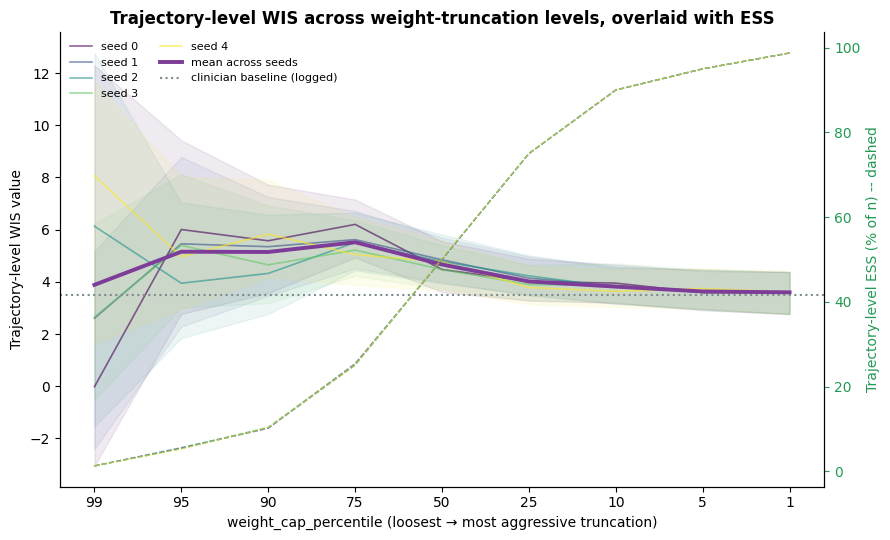

In [24]:
save_path_traj = os.path.join(cql_model_dir, "weight_truncation_sweep_results_traj.png")
fig_traj = evwis.plot_weight_truncation_sweep(sweep_rows, estimator="trajectory", save_path=save_path_traj)

Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/weight_truncation_sweep_results_step.png


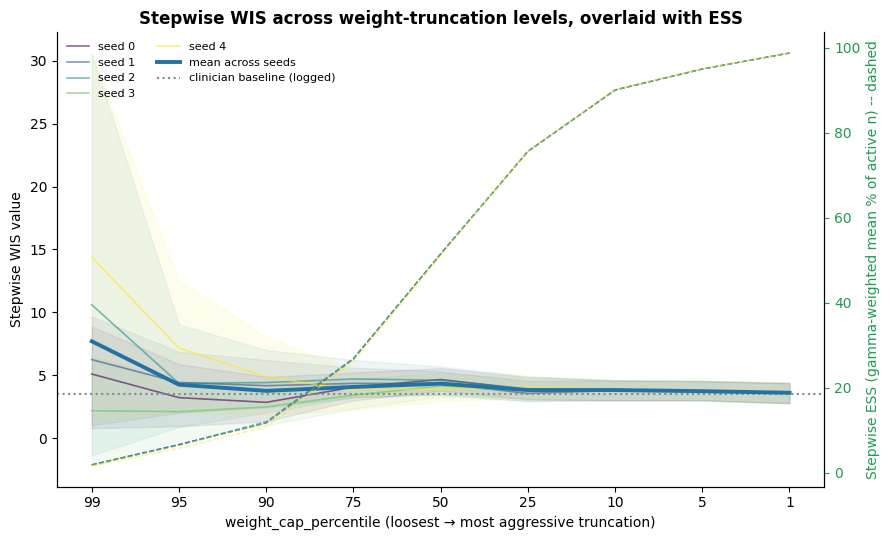

In [25]:
save_path_step = os.path.join(cql_model_dir, "weight_truncation_sweep_results_step.png")
fig_step = evwis.plot_weight_truncation_sweep(sweep_rows, estimator="stepwise", save_path=save_path_step)

In [28]:
import torch

worst_rows = [3591, 5902, 5903, 3587, 5901]  # same rows diagnosed earlier
device = "cuda" if torch.cuda.is_available() else "cpu"
states_t = torch.as_tensor(active_processor.rl_dataset["states"][worst_rows], dtype=torch.float32).to(device)
actions_t = torch.as_tensor(active_processor.rl_dataset["actions"][worst_rows], dtype=torch.float32).to(device)

cql_actor = evwis.get_cql_actor(cql_models_with_seeds[0])   # pick one seed to start
bc_actor = evwis.get_bc_actor(bc_models_with_seeds[0])

# CQL's own std vs BC's std at these specific states -- is it actually wider?
f_gate_logit, v_gate_logit, f_raw_mean, v_raw_mean, f_std_cql, v_std_cql = cql_actor._dists(states_t)
_, _, _, (_, _, _, _, bc_f_std, bc_v_std) = bc_actor(states_t, return_dist=True)

print("v_std_cql:", v_std_cql.squeeze().tolist())
print("bc_v_std: ", bc_v_std.squeeze().tolist())
print("v_raw_mean (CQL's chosen logit-dose):", v_raw_mean.squeeze().tolist())

# Now compare the actual log-probs, unclipped, both std sources
lp_bc_unclipped = evwis.log_prob_for_wis_clipped(
    cql_actor, bc_actor, states_t, actions_t, logit_clip=None, z_clip=None, std_source="bc",
)
lp_cql_unclipped = evwis.log_prob_for_wis_clipped(
    cql_actor, bc_actor, states_t, actions_t, logit_clip=None, z_clip=None, std_source="cql",
)
print("log-ratio, BC std, unclipped: ", lp_bc_unclipped.tolist())
print("log-ratio, CQL std, unclipped:", lp_cql_unclipped.tolist())

v_std_cql: [2.7182817459106445, 0.5592731833457947, 0.5595874786376953, 2.7182817459106445, 0.5463045835494995]
bc_v_std:  [0.7055481672286987, 0.24344807863235474, 0.24466370046138763, 0.7028713822364807, 0.2483629584312439]
v_raw_mean (CQL's chosen logit-dose): [-28.591341018676758, -18.16402816772461, -18.080759048461914, -26.495609283447266, -17.773168563842773]
log-ratio, BC std, unclipped:  [-2551.068115234375, -2292.95361328125, -2247.288330078125, -2163.74853515625, -2100.030029296875]
log-ratio, CQL std, unclipped: [-41.21951675415039, -437.70147705078125, -432.8104553222656, -33.51846694946289, -437.0284729003906]


# this is what we're using

In [30]:
cql_actor_0 = evwis.get_cql_actor(cql_models_with_seeds[0])
bc_actor_0 = evwis.get_bc_actor(bc_models_with_seeds[0])

behavior_lp_cql, target_lp_cql = evwis.compute_behavior_and_target_log_probs(
    cql_actor_0, bc_actor_0,
    active_processor.rl_dataset["states"], active_processor.rl_dataset["actions"],
    logit_clip=8.0, z_clip=10.0, std_source="cql",
)
log_ratio_cql = target_lp_cql - behavior_lp_cql

print("per-step log_ratio (std_source='cql'):")
print(f"  mean={log_ratio_cql.mean():.3f}, std={log_ratio_cql.std():.3f}, "
      f"min={log_ratio_cql.min():.3f}, max={log_ratio_cql.max():.3f}")
print(f"  99.9th pctile: {np.percentile(log_ratio_cql, 99.9):.3f}, "
      f"0.1th pctile: {np.percentile(log_ratio_cql, 0.1):.3f}")

per-step log_ratio (std_source='cql'):
  mean=-4.903, std=12.445, min=-83.536, max=74.728
  99.9th pctile: 10.730, 0.1th pctile: -58.376


In [ ]:
results_cql_std = evwis.run_wis_across_seeds(
    cql_models_with_seeds, bc_models_with_seeds, active_processor,
    gamma=0.975, logit_clip=8.0, z_clip=10.0,
    std_source="cql",
)

CQL seeds loaded: [0, 1, 2, 3, 4]
BC seeds loaded:  [0, 1, 2, 3, 4]
Matched 5 (CQL, BC) pairs by results.json seed: [0, 1, 2, 3, 4]

=== Seed 0 ===
  [std_source=cql]
  Clinician baseline (logged) return: 3.4876 +/- 0.3981 (SEM)
  Trajectory-level WIS: 1.2029  [-1.1558, 7.6556]  ESS=2.0/240 (0.8%)
  Stepwise WIS:         0.8039  [-3.9842, 4.5028]
  Myopic per-decision WIS (non-cumulative, sanity-check only): -3.6952  [-4.9521, 1.8853]
  Top-1% of trajectories hold 100.0% of total weight (max single trajectory: 54.3%)

=== Seed 1 ===
  [std_source=cql]
  Clinician baseline (logged) return: 3.4876 +/- 0.3981 (SEM)
  Trajectory-level WIS: -1.1508  [-1.1558, 5.0934]  ESS=1.0/240 (0.4%)
  Stepwise WIS:         3.6512  [-1.4995, 6.7771]
  Myopic per-decision WIS (non-cumulative, sanity-check only): -1.2251  [-3.6075, 3.5082]
  Top-1% of trajectories hold 100.0% of total weight (max single trajectory: 99.9%)

=== Seed 2 ===
  [std_source=cql]
  Clinician baseline (logged) return: 3.4876 +/- 0

In [9]:
def _to_native(row):
    return {k: (float(v) if hasattr(v, "item") else v) for k, v in row.items()}

In [10]:
sweep_rows_cql_std = evwis.run_weight_truncation_sweep(
    cql_models_with_seeds, bc_models_with_seeds, active_processor,
    wcap_values=[99.0, 95.0, 90.0, 75.0, 50.0, 25.0, 10.0, 5.0, 1.0],
    gamma=0.975, n_bootstrap=300, random_state=0,
    logit_clip=8.0, z_clip=10.0, std_source="cql",
)

sweep_data_path = os.path.join(cql_model_dir, "weight_truncation_sweep_cql_std.json")
with open(sweep_data_path, "w") as f:
    json.dump([_to_native(r) for r in sweep_rows_cql_std], f, indent=2)
print(f"Saved weight truncation sweep results (std_source='cql') to {sweep_data_path}")

CQL seeds loaded: [0, 1, 2, 3, 4]
BC seeds loaded:  [0, 1, 2, 3, 4]
Matched 5 (CQL, BC) pairs by results.json seed: [0, 1, 2, 3, 4]

=== Seed 0: building trajectories once, then sweeping 9 cap levels ===
  wcap= 99.0  traj=2.649 (traj ESS 1.2%)  step=-0.101 (step ESS 2.0%)
  wcap= 95.0  traj=5.314 (traj ESS 5.4%)  step=1.895 (step ESS 6.4%)
  wcap= 90.0  traj=6.406 (traj ESS 10.4%)  step=2.905 (step ESS 11.3%)
  wcap= 75.0  traj=5.368 (traj ESS 25.4%)  step=4.380 (step ESS 26.7%)
  wcap= 50.0  traj=4.788 (traj ESS 50.1%)  step=4.536 (step ESS 51.5%)
  wcap= 25.0  traj=4.304 (traj ESS 75.0%)  step=3.956 (step ESS 75.7%)
  wcap= 10.0  traj=3.859 (traj ESS 90.0%)  step=3.702 (step ESS 90.0%)
  wcap=  5.0  traj=3.617 (traj ESS 95.0%)  step=3.715 (step ESS 95.0%)
  wcap=  1.0  traj=3.592 (traj ESS 98.8%)  step=3.582 (step ESS 98.8%)

=== Seed 1: building trajectories once, then sweeping 9 cap levels ===
  wcap= 99.0  traj=2.649 (traj ESS 1.3%)  step=1.239 (step ESS 1.8%)
  wcap= 95.0  traj=

Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/weight_truncation_sweep_results_traj_cql_std.png


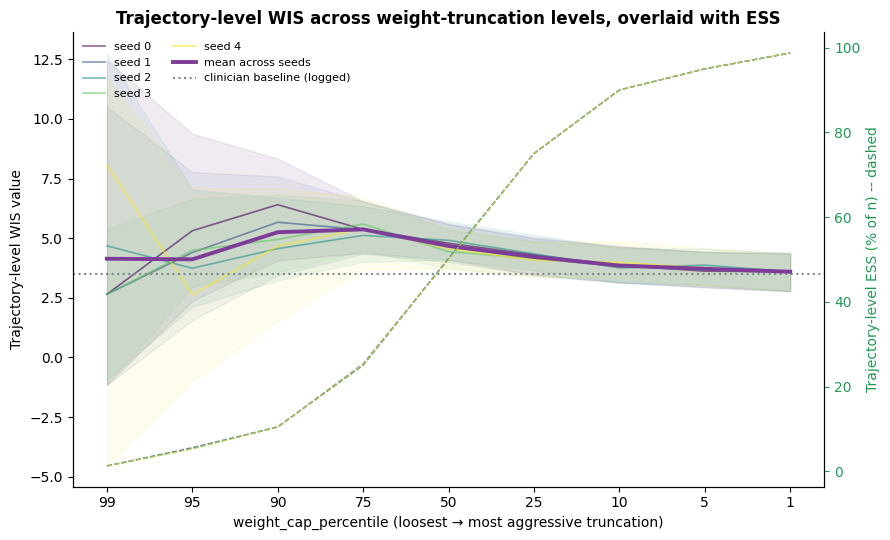

In [11]:
save_path_traj_cql = os.path.join(cql_model_dir, "weight_truncation_sweep_results_traj_cql_std.png")
fig_traj_cql = evwis.plot_weight_truncation_sweep(sweep_rows_cql_std, estimator="trajectory", save_path=save_path_traj_cql)

Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/weight_truncation_sweep_results_step_cql_std.png


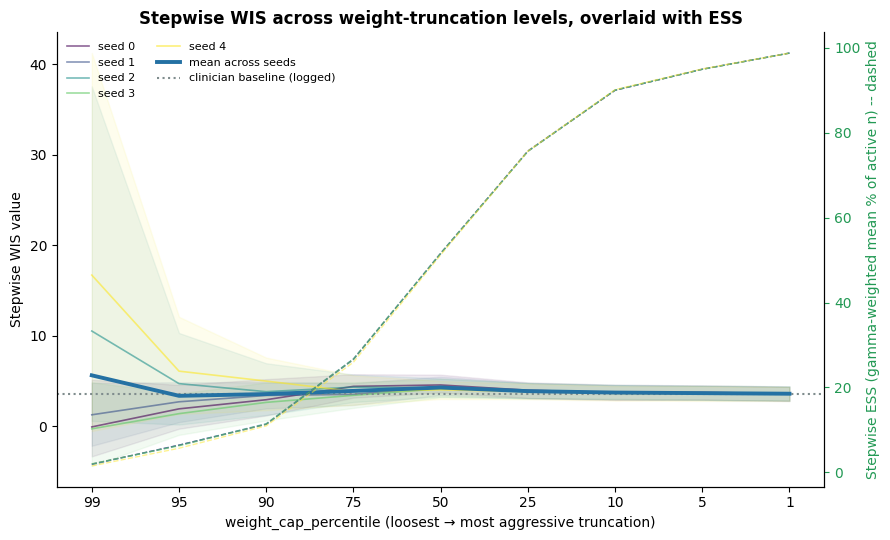

In [36]:
save_path_step_cql = os.path.join(cql_model_dir, "weight_truncation_sweep_results_step_cql_std.png")
fig_step_cql = evwis.plot_weight_truncation_sweep(sweep_rows_cql_std, estimator="stepwise", save_path=save_path_step_cql)

**Note on comparing the two estimators:** trajectory-level and stepwise WIS 
will not numerically agree even under a null policy shift, because trajectories 
have different lengths -- stepwise WIS normalizes by the trajectories still active 
at each timestep, not by the fixed total N. A gap between the two on its own is not 
evidence of a bug; use the bootstrap CIs and the ESS curve below to judge which 
(if either) estimate to trust at the horizons involved.

In [ ]:
fig = evwis.plot_weight_diagnostics(
    results,
    save_path=os.path.join(cql_model_dir, f"wis_weight_diagnostics_{ACTIVE_SPLIT}.png"),
)
fig


In [ ]:
fig = evwis.plot_bootstrap_distributions(
    results,
    save_path=os.path.join(cql_model_dir, f"wis_bootstrap_distributions_{ACTIVE_SPLIT}.png"),
)
fig


In [ ]:
fig = evwis.plot_stepwise_ess_curve(
    results,
    save_path=os.path.join(cql_model_dir, f"wis_stepwise_ess_{ACTIVE_SPLIT}.png"),
)
fig


## Robustness check: capped vs. uncapped importance weights

Re-runs the same analysis with per-timestep log importance ratios capped
at the 1st/99th percentile (pooled across all timesteps), to check
whether the headline WIS values are being driven by a small number of
extreme single-timestep ratios -- the same kind of dominance BC's own
docstring flagged for the fluid gate specifically. If capped and
uncapped values diverge substantially, that's a sign the uncapped
estimate is not trustworthy on its own.

In [ ]:
results_capped = evwis.run_wis_across_seeds(
    cql_models, bc_models, cql_model_dirs, bc_model_dirs,
    active_processor,
    gamma=GAMMA,
    cap_percentile=1.0,
    n_bootstrap=1000,
    random_state=0,
)


In [ ]:
for r_raw, r_capped in zip(results, results_capped):
    assert r_raw["seed"] == r_capped["seed"]
    print(f"seed {r_raw['seed']}: "
          f"trajectory WIS raw={r_raw['trajectory_wis']['value']:.4f} vs capped={r_capped['trajectory_wis']['value']:.4f}  |  "
          f"stepwise WIS raw={r_raw['stepwise_wis']['value']:.4f} vs capped={r_capped['stepwise_wis']['value']:.4f}")


## Once val looks sane: rerun on test

Set `ACTIVE_SPLIT = "test"` in the cell above (under "Run WIS --
validation set first") and re-run every cell from that point down. Keep
both the val and test result dicts (e.g. rename to `results_val` /
`results_test` before switching) so you can compare val-vs-test weight
diagnostics as an extra sanity check, same as this project has done for
every other stage-3 analysis.